## Import libraries and configure the environment

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys
from pathlib import Path

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

PROJECT_ROOT = Path.cwd().parent
# Reproducibility
SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)

# Select computation device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Selected device:", device)

PyTorch version: 2.15.0+cpu
CUDA available: False
Selected device: cpu


## Understand the input data

Our Human Activity Recognition dataset contains six sensor channels
recorded over 128 time steps for each sample.

The CNN expects input in the following format:

(batch_size, channels, sequence_length)

For a batch size of 64, the expected shape is:

(64, 6, 128)

In [3]:

# Create a sample batch to understand the input dimensions
dummy_input = torch.randn(64, 6, 128)

print("Input shape:", dummy_input.shape)
print("Batch size:", dummy_input.shape[0])
print("Number of sensor channels:", dummy_input.shape[1])
print("Time steps per sample:", dummy_input.shape[2])


Input shape: torch.Size([64, 6, 128])
Batch size: 64
Number of sensor channels: 6
Time steps per sample: 128


## Load prepared datasets

Load the preprocessed sensor signals, activity labels, and
participant-independent training and validation split.

In [4]:

import sys
from torch.utils.data import Dataset, DataLoader, Subset

# Make the project root available for importing paths.py
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Import centralized project paths
from paths import PROJECT_ROOT, DATA_DIR

# Define the processed data file
PROCESSED_DATA_FILE = DATA_DIR / "processed" / "har_preprocessed.pt"

# Load saved data
data = torch.load(
    PROCESSED_DATA_FILE,
    map_location=device,
    weights_only=False
)

# Retrieve tensors and split indices
X_train_tensor = data["X_train"]
X_test_tensor = data["X_test"]

y_train_tensor = data["y_train"]
y_test_tensor = data["y_test"]

train_indices = data["train_indices"]
val_indices = data["val_indices"]

print("Data loaded successfully!")
print("Training signals:", X_train_tensor.shape)
print("Training labels:", y_train_tensor.shape)
print("Testing signals:", X_test_tensor.shape)
print("Testing labels:", y_test_tensor.shape)
print("Training indices:", len(train_indices))
print("Validation indices:", len(val_indices))


Data loaded successfully!
Training signals: torch.Size([7352, 6, 128])
Training labels: torch.Size([7352])
Testing signals: torch.Size([2947, 6, 128])
Testing labels: torch.Size([2947])
Training indices: 5551
Validation indices: 1801


## Create PyTorch datasets

Create a custom Dataset to organize sensor signals and their
corresponding activity labels.

In [5]:

class HAR_Dataset(Dataset):

    def __init__(self, signals, labels):
        self.signals = signals
        self.labels = labels

    def __len__(self):
        return len(self.signals)

    def __getitem__(self, idx):
        return self.signals[idx], self.labels[idx]


# Create the complete training and testing datasets
train_dataset = HAR_Dataset(X_train_tensor, y_train_tensor)
test_dataset = HAR_Dataset(X_test_tensor, y_test_tensor)

print("Training dataset size:", len(train_dataset))
print("Testing dataset size:", len(test_dataset))


Training dataset size: 7352
Testing dataset size: 2947


In [6]:
# Create training and validation subsets
train_subset = Subset(train_dataset, train_indices)
val_subset = Subset(train_dataset, val_indices)

print("Training subset size:", len(train_subset))
print("Validation subset size:", len(val_subset))


Training subset size: 5551
Validation subset size: 1801


In [7]:
# Create DataLoaders

BATCH_SIZE = 64

train_loader = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_subset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))


Training batches: 87
Validation batches: 29
Testing batches: 47


In [8]:

# Get one batch from the training DataLoader
signals, labels = next(iter(train_loader))

print("Signal batch shape:", signals.shape)
print("Label batch shape:", labels.shape)

print("Signal data type:", signals.dtype)
print("Label data type:", labels.dtype)

print("First sample label:", labels[0].item())
print("First sample signal shape:", signals[0].shape)


Signal batch shape: torch.Size([64, 6, 128])
Label batch shape: torch.Size([64])
Signal data type: torch.float32
Label data type: torch.int64
First sample label: 1
First sample signal shape: torch.Size([6, 128])


## 3. Define the CNN Architecture

In [9]:

class HAR_CNN(nn.Module):

    def __init__(self, num_classes=6):
        super().__init__()

        # First convolutional block
        self.conv1 = nn.Conv1d(
            in_channels=6,
            out_channels=32,
            kernel_size=5,
            padding=2
        )
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool1d(kernel_size=2)

        # Second convolutional block
        self.conv2 = nn.Conv1d(
            in_channels=32,
            out_channels=64,
            kernel_size=5,
            padding=2
        )
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool1d(kernel_size=2)

        # Classification layers
        self.flatten = nn.Flatten()

        self.fc1 = nn.Linear(
            in_features=64 * 32,
            out_features=128
        )
        self.relu3 = nn.ReLU()

        self.fc2 = nn.Linear(
            in_features=128,
            out_features=num_classes
        )

    def forward(self, x):

        # First convolutional block
        x = self.conv1(x)
        x = self.relu1(x)
        x = self.pool1(x)

        # Second convolutional block
        x = self.conv2(x)
        x = self.relu2(x)
        x = self.pool2(x)

        # Classification
        x = self.flatten(x)
        x = self.fc1(x)
        x = self.relu3(x)
        x = self.fc2(x)

        return x


## Create the model and test its output

In [10]:

# Create the model
model = HAR_CNN(num_classes=6).to(device)

# Get one batch from the training DataLoader
signals_batch, labels_batch = next(iter(train_loader))

# Move batch to the selected device
signals_batch = signals_batch.to(device)
labels_batch = labels_batch.to(device)

# Perform a forward pass
outputs = model(signals_batch)

# Inspect the results
print("Input shape:", signals_batch.shape)
print("Output shape:", outputs.shape)

# Count trainable parameters
total_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", total_params)


Input shape: torch.Size([64, 6, 128])
Output shape: torch.Size([64, 6])
Trainable parameters: 274342


In [11]:

# Inspect predictions for the first five samples

model.eval()

with torch.no_grad():
    sample_outputs = model(signals_batch[:5])

    predicted_classes = torch.argmax(
        sample_outputs,
        dim=1
    )

print("Raw model outputs:")
print(sample_outputs)

print("\nPredicted class indices:")
print(predicted_classes)

print("\nActual class indices:")
print(labels_batch[:5])


Raw model outputs:
tensor([[-0.0269, -0.0837, -0.0311,  0.0562, -0.0863,  0.0778],
        [-0.0274, -0.0907, -0.0376,  0.0577, -0.0821,  0.0823],
        [-0.0269, -0.0839, -0.0316,  0.0565, -0.0866,  0.0779],
        [-0.0283, -0.0924, -0.0226,  0.0586, -0.0950,  0.0851],
        [-0.0176, -0.0974, -0.0048,  0.0486, -0.0879,  0.0830]])

Predicted class indices:
tensor([5, 5, 5, 5, 5])

Actual class indices:
tensor([4, 0, 5, 0, 1])


## Configure loss function and optimizer

In [12]:
# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

## Implement the Training Function

In [13]:

def train_one_epoch(model, train_loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    for signals, labels in train_loader:

        # Move data to the selected device
        signals = signals.to(device)
        labels = labels.to(device)

        # Clear gradients from the previous batch
        optimizer.zero_grad()

        # Forward pass
        outputs = model(signals)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update model weights
        optimizer.step()

        # Track loss
        running_loss += loss.item() * signals.size(0)

        # Calculate predictions
        predictions = torch.argmax(outputs, dim=1)

        correct_predictions += (predictions == labels).sum().item()
        total_samples += labels.size(0)

    epoch_loss = running_loss / total_samples
    epoch_accuracy = correct_predictions / total_samples

    return epoch_loss, epoch_accuracy


## Train for one epoch

In [14]:
train_loss, train_accuracy = train_one_epoch(
    model,
    train_loader,
    criterion,
    optimizer,
    device
)

print(f"Training Loss: {train_loss:.4f}")
print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Training Accuracy (%): {train_accuracy * 100:.2f}%")

Training Loss: 1.1097
Training Accuracy: 0.4342
Training Accuracy (%): 43.42%


## Implement the Validation Function

In [16]:

def validate_one_epoch(model, val_loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    with torch.no_grad():

        for signals, labels in val_loader:

            # Move data to the selected device
            signals = signals.to(device)
            labels = labels.to(device)

            # Forward pass
            outputs = model(signals)

            # Calculate loss
            loss = criterion(outputs, labels)

            # Track loss
            running_loss += loss.item() * signals.size(0)

            # Calculate predictions
            predictions = torch.argmax(outputs, dim=1)

            correct_predictions += (predictions == labels).sum().item()
            total_samples += labels.size(0)

    epoch_loss = running_loss / total_samples
    epoch_accuracy = correct_predictions / total_samples

    return epoch_loss, epoch_accuracy


In [17]:

val_loss, val_accuracy = validate_one_epoch(
    model,
    val_loader,
    criterion,
    device
)

print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_accuracy:.4f}")
print(f"Validation Accuracy (%): {val_accuracy * 100:.2f}%")


Validation Loss: 0.8571
Validation Accuracy: 0.5591
Validation Accuracy (%): 55.91%


## 7. Multi-Epoch Training

In [18]:

NUM_EPOCHS = 20

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(NUM_EPOCHS):

    # Training
    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    # Validation
    val_loss, val_accuracy = validate_one_epoch(
        model,
        val_loader,
        criterion,
        device
    )

    # Save metrics
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    # Display results
    print(f"Epoch [{epoch + 1}/{NUM_EPOCHS}]")
    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_accuracy * 100:.2f}%")
    print(f"Val Loss:   {val_loss:.4f} | Val Accuracy:   {val_accuracy * 100:.2f}%")
    print("-" * 60)


Epoch [1/20]
Train Loss: 0.6974 | Train Accuracy: 62.55%
Val Loss:   0.7138 | Val Accuracy:   62.58%
------------------------------------------------------------
Epoch [2/20]
Train Loss: 0.6383 | Train Accuracy: 63.79%
Val Loss:   0.7059 | Val Accuracy:   62.47%
------------------------------------------------------------
Epoch [3/20]
Train Loss: 0.6190 | Train Accuracy: 65.84%
Val Loss:   0.6577 | Val Accuracy:   68.41%
------------------------------------------------------------
Epoch [4/20]
Train Loss: 0.6035 | Train Accuracy: 66.49%
Val Loss:   0.6909 | Val Accuracy:   64.58%
------------------------------------------------------------
Epoch [5/20]
Train Loss: 0.5806 | Train Accuracy: 68.51%
Val Loss:   0.6667 | Val Accuracy:   65.02%
------------------------------------------------------------
Epoch [6/20]
Train Loss: 0.5694 | Train Accuracy: 68.60%
Val Loss:   0.6739 | Val Accuracy:   67.07%
------------------------------------------------------------
Epoch [7/20]
Train Loss: 0.5

## Training Performance Visualization

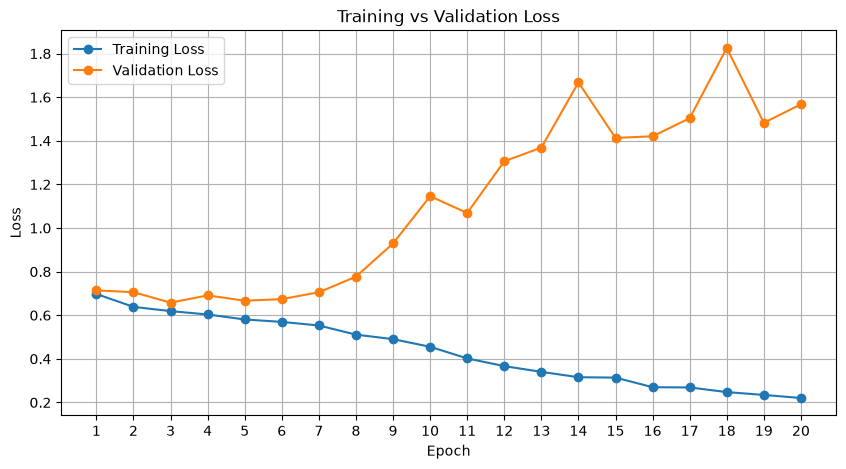

In [19]:

epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(10, 5))

plt.plot(epochs, history["train_loss"], marker="o", label="Training Loss")
plt.plot(epochs, history["val_loss"], marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.xticks(list(epochs))
plt.show()


## Training and validation accuracy

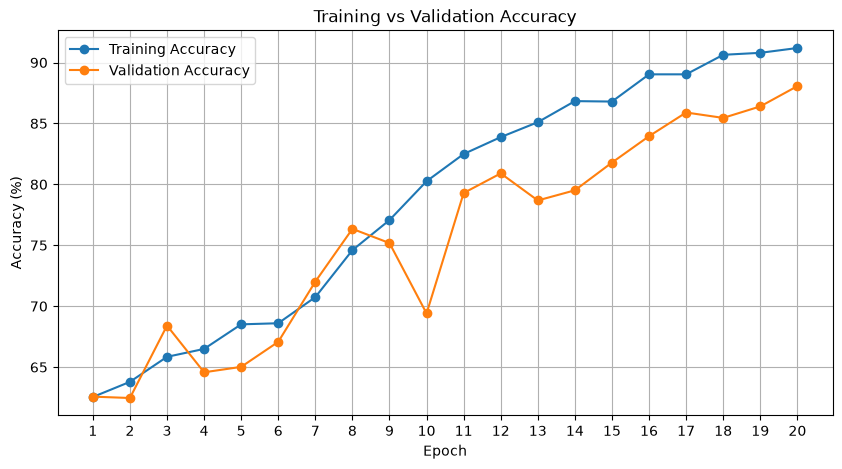

In [20]:

plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    [x * 100 for x in history["train_accuracy"]],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs,
    [x * 100 for x in history["val_accuracy"]],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.xticks(list(epochs))
plt.show()


## Identify the best validation epoch

In [21]:

best_loss_epoch = np.argmin(history["val_loss"]) + 1
best_accuracy_epoch = np.argmax(history["val_accuracy"]) + 1

print("Best validation loss:")
print(f"Epoch: {best_loss_epoch}")
print(f"Loss: {min(history['val_loss']):.4f}")

print("\nBest validation accuracy:")
print(f"Epoch: {best_accuracy_epoch}")
print(f"Accuracy: {max(history['val_accuracy']) * 100:.2f}%")


Best validation loss:
Epoch: 3
Loss: 0.6577

Best validation accuracy:
Epoch: 20
Accuracy: 88.06%


## 9. Validation Performance Analysis

In [22]:

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for signals, labels in val_loader:

        signals = signals.to(device)

        outputs = model(signals)

        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

activity_names = [
    "WALKING",
    "WALKING_UPSTAIRS",
    "WALKING_DOWNSTAIRS",
    "SITTING",
    "STANDING",
    "LAYING"
]

print("Validation Classification Report:\n")

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=activity_names,
        digits=4
    )
)


Validation Classification Report:

                    precision    recall  f1-score   support

           WALKING     0.9941    0.9941    0.9941       338
  WALKING_UPSTAIRS     0.9443    0.9819    0.9627       276
WALKING_DOWNSTAIRS     0.9793    0.9793    0.9793       242
           SITTING     0.7619    0.8737    0.8140       293
          STANDING     0.7664    0.8380    0.8006       321
            LAYING     0.8785    0.6556    0.7509       331

          accuracy                         0.8806      1801
         macro avg     0.8874    0.8871    0.8836      1801
      weighted avg     0.8849    0.8806    0.8788      1801



## Confusion matrix

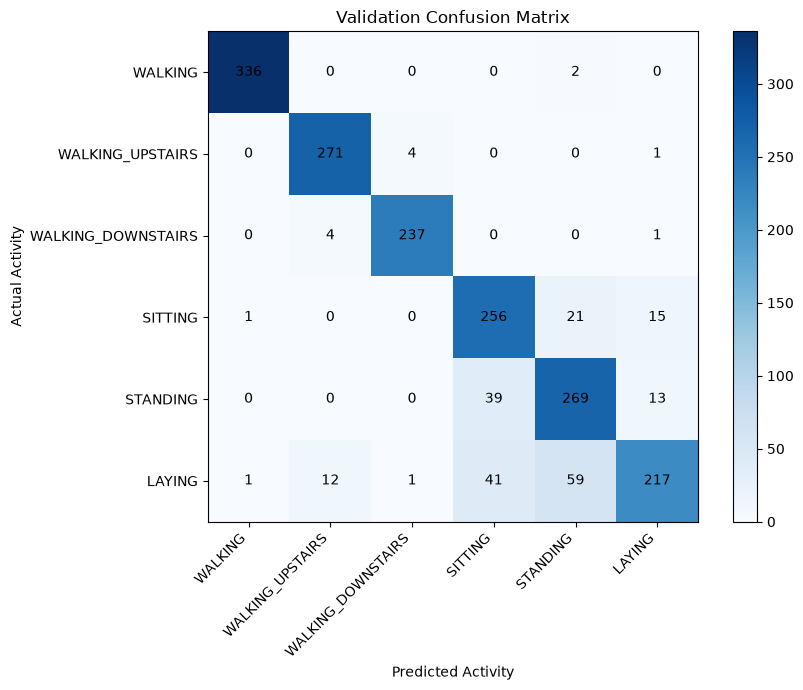

In [23]:

cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(9, 7))

plt.imshow(cm, interpolation="nearest", cmap="Blues")
plt.title("Validation Confusion Matrix")
plt.colorbar()

plt.xticks(
    range(len(activity_names)),
    activity_names,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(activity_names)),
    activity_names
)

plt.xlabel("Predicted Activity")
plt.ylabel("Actual Activity")

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()
